# Overnight overshoot portfolio — optimal-portfolio system on the close→open reversal alpha

This is `../optimizer/optimal_portfolio.ipynb` **wired to a different alpha and a different
holding period**. The optimizer, risk model, cost/impact models, PnL accounting, diagnostics
and parameter sweeps are the *same code*; what changes is the data preamble and the forecast,
both taken from `overnight_overshoot_study.ipynb`.

1) Forecast — the **overnight reversal** model (close-auction overshoot → next-open return)
2) Risk model (factor model, unchanged)
3) Cost model (spread + commission; here a half-spread at **each** auction)
4) Optimization framework (with scaling and factor sparsity for numerical stability)

### The trade (differs from the close-auction strategy)
- **Entry:** the **closing auction** on day *t* (`stat_type == 11`).
- **Exit:** the **next opening auction** on day *t+1* (`stat_type == 1`).
- So the book is **held overnight**, not flat at the close.

### Column contract
So that every downstream cell runs unchanged, the assembled frame reuses
`optimal_portfolio.ipynb`'s names with the new execution meaning:

| column | here | in `optimal_portfolio.ipynb` |
|---|---|---|
| `entry_price` | closing auction price, day *t* | 15:50 mid |
| `auction_price` | **next** day's opening auction price | closing auction price |
| `return_to_close` | the **overnight** return | 15:50 → 16:00 return |
| `spread_return` | close spread **+** next-open spread | quoted spread at 15:50 |
| `entry_mid` | 15:50 mid — only feeds the overshoot feature | *(n/a)* |

### Issues
- Covariance matrix currently still in standardized returns. Need to change units by adding the garch modeled term.
- The risk model is a **close-to-close daily** covariance used for an **overnight** holding
  period, so expected vol is overstated (conservative). Days are also no longer independent —
  the book is live overnight — which the "each day is its own QP" framing ignores.

## Gathering Data

Same preamble as `overnight_overshoot_study.ipynb` — imbalance / tbbo / statistics over the
2025-06-11 .. 2026-06-11 window on `top_100_universe.txt` — keeping the **opening** auction
(`stat_type == 1`) alongside the closing one.

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
with open("../top_100_universe.txt", "r") as f:
    ACTIVE_SET = [line.strip() for line in f]
START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"

# Close-auction imbalance print (reference imbalance ~10 min before the close)
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE, start_date=START, end_date=END, dataset=DATASET, schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty", "paired_qty", "ref_price"])
    .with_columns(
        pl.col("ts_event").dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical),
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(9, 30), pl.time(16, 0)),
            pl.col("symbol").is_in(ACTIVE_SET))
)

# Trades with the bbo (for pre-close mid, ADV, daily vol, auction spreads, and the open mid)
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE, start_date=START, end_date=END, dataset=DATASET, schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(13, 30), pl.time(21, 0)),
            pl.col("symbol").is_in(ACTIVE_SET))
    .with_columns(pl.col("ts_event").dt.convert_time_zone("America/New_York"))
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(9, 30), pl.time(16, 0)))
    .with_columns(pl.col("symbol").cast(pl.Categorical))
)

# statistics: closing auction (stat_type == 11) AND opening auction (stat_type == 1)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE, start_date=START, end_date=END, dataset=DATASET, schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col("ts_event").dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical),
    )
    .filter(pl.col("stat_type").is_in([1, 11]),
            pl.col("symbol").is_in(ACTIVE_SET))
)

CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/.claude/worktrees/overnight-optimizer-nb/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet


### Daily aggregates

One row per `(date, symbol)`. The causal ADV / daily-vol recipes are lifted verbatim from
`optimal_portfolio.ipynb` (EWMA, shifted one day, so day *t* uses only info `< t`); the auction
prices, pre-auction mid, open mid and imbalance print come from `overnight_overshoot_study.ipynb`.

In [2]:
avg_daily_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("day_volume")
    )
    .sort(["date", "symbol"])
    .with_columns(
    pl.col("day_volume").ewm_mean(span=10, adjust=True).shift(1).over("symbol").alias("ADV")
    )
    .drop("day_volume")
    .collect(engine="streaming")
)

# Causal per-(date, symbol) daily volatility: EWMA of squared daily returns, SHIFTED 1 day (uses only
# past info) -- same causal recipe as ADV.  sigma_{i,d} = sqrt( EWMA(day_ret^2) )_{d-1}, day close = last mid.
daily_vol = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"),
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,0)))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(pl.col("mid").last().alias("close"))
    .sort(["date", "symbol"])
    .with_columns(pl.col("close").pct_change().over("symbol").alias("day_ret"))
    .with_columns(
        pl.col("day_ret").pow(2).ewm_mean(span=10, adjust=True).shift(1).over("symbol").sqrt().alias("vol")
    )
    .select(["date", "symbol", "vol"])
    .collect(engine="streaming")
)

# Official auction prices -- the two legs we actually transact in.
close_auction = (
    df_stats.filter(pl.col("stat_type") == 11)
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .select("date", "symbol", pl.col("price").alias("close_auction_price"))
    .collect(engine="streaming")
)
open_auction = (
    df_stats.filter(pl.col("stat_type") == 1)
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .select("date", "symbol", pl.col("price").alias("open_auction_price"))
    .collect(engine="streaming")
)

# Pre-auction mid at ~15:50 -- the fair-value reference the close overshoot is measured against.
# NOT an execution price here (we enter in the close cross), only a feature input.
entry_mid = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"),
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15, 49, 55), pl.time(15, 50, 0)))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(pl.col("mid").last().alias("entry_mid"))
    .collect(engine="streaming")
)

# Quoted relative spread at BOTH auction ends.  An auction clears at one price with no bid/ask to
# cross, but MOC/MOO fills are not free -- we charge a half-spread at each end as the cost proxy.
# `close_spread` = mean quoted spread over the last 5 min of day t; `open_spread` = mean over the
# first 5 min of day t (aligned to the NEXT day below).  Downstream
# `spread_return = close_spread + next_open_spread`, so the PnL cell's `0.5 * spread_return` is
# exactly one half-spread at each auction -- the accounting code stays byte-identical.
auction_spreads = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"),
    )
    .with_columns(((pl.col("ask_px_00") - pl.col("bid_px_00")) / pl.col("mid")).alias("rel_spread"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col("rel_spread")
          .filter(pl.col("ts_event").dt.time().is_between(pl.time(15, 55), pl.time(16, 0)))
          .mean().alias("close_spread"),
        pl.col("rel_spread")
          .filter(pl.col("ts_event").dt.time().is_between(pl.time(9, 30), pl.time(9, 35)))
          .mean().alias("open_spread"),
    )
    .collect(engine="streaming")
)

# Open + first few minutes mid (~09:33-09:35) -- the alternative "slightly after the open cross" exit
open_5min = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"),
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(9, 33), pl.time(9, 35)))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(pl.col("mid").mean().alias("open_5min_mid"))
    .collect(engine="streaming")
)

# Late-day drift into the close (15:45 -> 15:50) -- momentum context for the overshoot
recent_return = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"),
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15, 45, 0), pl.time(15, 50, 0)))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(((pl.col("mid").last() - pl.col("mid").first()) / pl.col("mid").first()).alias("recent_return"))
    .collect(engine="streaming")
)

# The reference close-auction imbalance print (first message in the 15:50:00-15:50:05 window)
imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15, 50, 0), pl.time(15, 50, 5)))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(pl.col(["side", "total_imbalance_qty", "paired_qty", "ref_price"]).first())
    .collect(engine="streaming")
)

### Assemble target + features

The **overnight exit** is the *next trading day's* open, so the open-side columns are shifted back
one row **within each symbol** (`shift(-1) over symbol`). That naturally spans weekends/holidays;
`gap_days <= 4` guards against a stale row masquerading as an overnight hold.

Every feature is known by 16:00 on day *t*, so there is no look-ahead. The alpha the optimizer
consumes is `overnight_return_xm` (cross-sectionally demeaned per day) — reversal ⇒ a **negative**
loading on `close_overshoot_xm`.

In [3]:
data = (
    imb_print
    .join(entry_mid,       on=["date", "symbol"])
    .join(close_auction,   on=["date", "symbol"])
    .join(open_auction,    on=["date", "symbol"])
    .join(open_5min,       on=["date", "symbol"])
    .join(auction_spreads, on=["date", "symbol"])
    .join(recent_return,   on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .join(daily_vol,       on=["date", "symbol"])
    .sort(["symbol", "date"])
    # --- overnight exit = NEXT trading day's open, shifted within symbol ---
    .with_columns(
        pl.col("open_auction_price").shift(-1).over("symbol", order_by="date").alias("next_open_auction"),
        pl.col("open_5min_mid").shift(-1).over("symbol", order_by="date").alias("next_open_5min"),
        pl.col("open_spread").shift(-1).over("symbol", order_by="date").alias("next_open_spread"),
        pl.col("date").shift(-1).over("symbol", order_by="date").alias("next_date"),
    )
    .with_columns((pl.col("next_date") - pl.col("date")).dt.total_days().alias("gap_days"))
    # --- signed dollar imbalance ---
    .with_columns(
        (pl.col("total_imbalance_qty") * pl.col("ref_price")).alias("dollar_imbalance"),
        (pl.col("paired_qty") * pl.col("ref_price")).alias("paired_dollars"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
        ).alias("sign"),
    )
    .with_columns((pl.col("sign") * pl.col("dollar_imbalance")).alias("signed_dollar_imbalance"))
    # --- EXECUTION COLUMNS: the names the rest of the notebook (cost model, PnL, sweeps) expects.
    #     entry_price   = the CLOSING auction price on day t   (we enter in the close cross)
    #     auction_price = the NEXT day's OPENING auction price (we exit in the open cross)
    #     spread_return = close-side + open-side quoted spread (a half-spread charged at each end)
    .with_columns(
        pl.col("close_auction_price").alias("entry_price"),
        pl.col("next_open_auction").alias("auction_price"),
        (pl.col("close_spread") + pl.col("next_open_spread")).alias("spread_return"),
    )
    .drop(["total_imbalance_qty"])
    .drop_nulls(subset=["entry_price", "auction_price", "entry_mid", "spread_return",
                        "next_open_5min", "ADV", "vol"])
    .filter(pl.col("gap_days") <= 4)  # drop stale/long-gap "overnights"
    # --- raw ratios, overshoot, and the overnight target ---
    .with_columns(
        (
            (pl.col("paired_dollars") / pl.col("ADV"))
        ).alias("auction_dollar_volume_ratio"),
        (
            pl.when(pl.col("paired_dollars") != 0).then(pl.col("signed_dollar_imbalance") / pl.col("paired_dollars"))
            .otherwise(0)
        ).alias("net_signed_imb"),
        (
            (pl.col("close_auction_price") - pl.col("entry_mid")) / pl.col("entry_mid")
        ).alias("close_overshoot"),
        # `return_to_close` keeps its name for downstream compatibility, but it IS the overnight
        # (close-auction -> next-open-auction) return.
        (
            (pl.col("auction_price") - pl.col("entry_price")) / pl.col("entry_price")
        ).alias("return_to_close"),
        (
            (pl.col("next_open_5min") - pl.col("entry_price")) / pl.col("entry_price")
        ).alias("overnight_return_5min"),
    )
    .with_columns(
        pl.col("net_signed_imb").rank().over(pl.col("date")).alias("rank_net_imb")
    )
    # --- cross-sectional (per-day) demeaning + rank + interactions ---
    .with_columns(
        (pl.col("return_to_close") - pl.col("return_to_close").mean().over("date")).alias("overnight_return_xm"),
        (pl.col("overnight_return_5min") - pl.col("overnight_return_5min").mean().over("date")).alias("overnight_return_5min_xm"),
        (pl.col("close_overshoot") - pl.col("close_overshoot").mean().over("date")).alias("close_overshoot_xm"),
        (pl.col("recent_return") - pl.col("recent_return").mean().over("date")).alias("recent_return_xm"),
        (pl.col("auction_dollar_volume_ratio") - pl.col("auction_dollar_volume_ratio").mean().over("date")).alias("auction_dollar_volume_ratio_xm"),
        (
            ((pl.col("net_signed_imb").rank().over(pl.col("date")) - pl.col("net_signed_imb").rank().min().over(pl.col("date")))
                / (pl.col("net_signed_imb").rank().max().over(pl.col("date")) - pl.col("net_signed_imb").rank().min().over(pl.col("date"))))
                * 2 - 1
        ).alias("norm_rank_net_imb"),
    )
    .with_columns(
        (pl.col("close_overshoot_xm") * pl.col("auction_dollar_volume_ratio_xm")).alias("overshoot_x_auction"),
        (pl.col("close_overshoot_xm") * pl.col("norm_rank_net_imb")).alias("overshoot_x_rank"),
        (pl.col("norm_rank_net_imb") * pl.col("auction_dollar_volume_ratio_xm")).alias("rank_x_auction"),
    )
    .sort(["date", "symbol"])
)

print(f"rows: {data.height:,}   dates: {data['date'].n_unique()}   symbols: {data['symbol'].n_unique()}")

rows: 16,499   dates: 243   symbols: 95


In [4]:
TEST_START = pl.date(2026, 1, 1)

# `overnight_overshoot_study.ipynb` fits the reversal ONLY on names whose closing auction was large
# relative to ADV (where the imbalance actually drove the print), so the backtest trades that same
# subset.  The threshold is the median over the TRAIN window only -- a fixed, causal number rather
# than the full-sample median, so the test period never informs its own filter.
AUCTION_RATIO_THRESH = float(
    data.filter(pl.col("date") < TEST_START)["auction_dollar_volume_ratio"].median()
)

test_data = data.filter(pl.col("date") >= TEST_START,
                        pl.col("auction_dollar_volume_ratio") > AUCTION_RATIO_THRESH)
print(f"auction/ADV threshold: {AUCTION_RATIO_THRESH:.4f}")
print(f"test rows: {test_data.height:,}   days: {test_data['date'].n_unique()}   "
      f"names/day: {test_data.height / test_data['date'].n_unique():.0f}")
test_data.head()

auction/ADV threshold: 0.2440
test rows: 4,200   days: 109   names/day: 39


date,symbol,side,paired_qty,ref_price,entry_mid,close_auction_price,open_auction_price,open_5min_mid,close_spread,open_spread,recent_return,ADV,vol,next_open_auction,next_open_5min,next_open_spread,next_date,gap_days,dollar_imbalance,paired_dollars,sign,signed_dollar_imbalance,entry_price,auction_price,spread_return,auction_dollar_volume_ratio,net_signed_imb,close_overshoot,return_to_close,overnight_return_5min,rank_net_imb,overnight_return_xm,overnight_return_5min_xm,close_overshoot_xm,recent_return_xm,auction_dollar_volume_ratio_xm,norm_rank_net_imb,overshoot_x_auction,overshoot_x_rank,rank_x_auction
date,cat,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,i64,f64,f64,i32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2026-01-02,"""AAPL""","""B""",2428652,270.51,270.48,271.01,272.05,272.853033,0.000054,0.000189,-0.000517,1.9679e9,0.005372,270.52,268.651149,0.000236,2026-01-05,3,1.3830e8,6.5697e8,1,1.3830e8,271.01,270.52,0.00029,0.333839,0.210516,0.001959,-0.001808,-0.008704,42.0,-0.012989,-0.021569,0.002029,0.000376,-0.072291,0.413793,-0.000147,0.00084,-0.029913
2026-01-02,"""ABNB""","""B""",182011,133.06,133.055,133.01,135.94,134.199766,0.000116,0.001907,0.00015,9.2872e7,0.008585,133.1,132.906685,0.001946,2026-01-05,3,1.5611e7,2.4218e7,1,1.5611e7,133.01,133.1,0.002063,0.260772,0.644598,-0.000338,0.000677,-0.000777,54.0,-0.010504,-0.013642,-0.000268,0.001043,-0.145357,0.827586,0.000039,-0.000222,-0.120296
2026-01-02,"""ADI""","""A""",306758,274.15,274.32,273.74,275.07,274.919608,0.000392,0.001913,-0.001674,1.2113e8,0.009605,279.72,282.36324,0.002811,2026-01-06,4,6.4508e7,8.4098e7,-1,-6.4508e7,273.74,279.72,0.003202,0.694274,-0.767061,-0.002114,0.021846,0.031502,6.0,0.010665,0.018637,-0.002045,-0.000781,0.288144,-0.827586,-0.000589,0.001692,-0.238464
2026-01-02,"""ADP""","""A""",111653,252.64,252.7,252.88,257.03,256.187889,0.000155,0.001908,-0.000791,8.3750e7,0.007921,252.69,252.80822,0.001747,2026-01-05,3,2.1980e7,2.8208e7,-1,-2.1980e7,252.88,252.69,0.001902,0.336813,-0.779218,0.000712,-0.000751,-0.000284,5.0,-0.011932,-0.013149,0.000782,0.000102,-0.069317,-0.862069,-0.000054,-0.000674,0.059756
2026-01-02,"""AEP""","""A""",675185,115.35,115.36,115.81,115.23,114.756923,0.000159,0.000912,-0.001039,5.5791e7,0.005771,115.57,115.172462,0.000931,2026-01-05,3,2.3379138e7,7.7883e7,-1,-2.3379138e7,115.81,115.57,0.00109,1.395982,-0.300184,0.003901,-0.002072,-0.005505,13.0,-0.013253,-0.01837,0.003971,-0.000146,0.989853,-0.586207,0.00393,-0.002328,-0.580259


In [5]:
[s for s in ACTIVE_SET if s not in test_data.select("symbol").unique().to_numpy()]

['CRWV', 'TEM', 'RGTI', 'EXE', 'ITCI']

## Daily MVO Optimizer

In [6]:
import cvxpy as cp
import scipy

class ForecastModel:
    def __init__(self, universe, model, features):
        self.universe = universe
        self.sym_idx_map = {s: i for i, s in enumerate(universe)}
        self.model = model
        self.features = features

    def get_alpha(self, day_df: pl.DataFrame) -> np.ndarray:
        alpha = np.zeros(len(self.universe))
        preds = self.model.predict(day_df[self.features].to_numpy()).ravel()  # scaled inside pipeline
        for symbol, p in zip(day_df["symbol"], preds):
            alpha[self.sym_idx_map[symbol]] = p
        return alpha

class CostModel:
    """Half-spread (in return space) per name; names with no quote -> large cost so the optimizer avoids them."""
    def __init__(self, universe: list):
        self.universe = universe
        self.sym_idx_map = {s:i for i, s in enumerate(universe)}

    def get_cost(self, day_df: pl.DataFrame, commission: float) -> np.ndarray:
        cost = np.zeros(len(self.universe))
        for symbol, spread, comm_rate in zip(day_df["symbol"], day_df["spread_return"], commission / day_df['entry_price']):
            cost[self.sym_idx_map[symbol]] = (2 * comm_rate)
        return cost

class ImpactModel:
    """Square-root market impact (Almgren/BARRA form):
        price impact  I_i    = gamma * sigma_i * sqrt(Q$_i / ADV$_i)           (a return; gamma ~ O(0..1))
        dollar cost   cost_i = gamma * sigma_i * |Q$_i|^{3/2} / sqrt(ADV$_i)   (= I_i * |Q$_i|)
    gamma is ONE scalar shared across names (swept separately).  sigma_i (daily return vol) AND ADV$ (daily
    $volume) are BOTH CAUSAL per-(name, date) columns on test_data (EWMA, shifted 1 day) -> only past info.
    Supplies the per-day, per-name impact coefficient  sigma_{i,d} / sqrt(ADV$_{i,d})  (ACTIVE_SET order),
    used by BOTH the optimizer objective and the PnL accounting so expected/realized impact stay consistent."""
    def __init__(self, universe: list):
        self.universe = universe
        self.sym_idx_map = {s: i for i, s in enumerate(universe)}

    def get_impact_coeff(self, day_df: pl.DataFrame) -> np.ndarray:
        v = np.zeros(len(self.universe))
        for symbol, vol, adv in zip(day_df["symbol"], day_df["vol"], day_df["ADV"]):
            if vol is not None and adv is not None and vol > 0 and adv > 0:
                v[self.sym_idx_map[symbol]] = vol / np.sqrt(adv)
        # names with no vol/ADV that day -> charge them like the highest-coeff present name (never "free" to trade)
        if (v == 0).any() and (v > 0).any():
            v[v == 0] = v[v > 0].max()
        return v

    def get_imbalance_caps(self, day_df: pl.DataFrame) -> np.ndarray:
            caps = np.zeros(len(self.universe))
            for symbol, imb in zip(day_df["symbol"], day_df["dollar_imbalance"]):
                if imb is not None and imb >= 100_000:
                    caps[self.sym_idx_map[symbol]] = 0.05 * imb
            # names PRESENT that day with a tiny imbalance -> cap at the smallest real cap (never uncapped).
            # CHANGED vs optimal_portfolio.ipynb: names ABSENT from the day's cross-section keep a cap of 0.
            # There, test_data held ~every ACTIVE_SET name every day; here we deliberately trade only the
            # large-auction subset, so ~half the universe is untradable on any given day and must not be
            # handed a positive cap -- otherwise the factor-neutrality equalities could park size in a name
            # with no alpha, no cost data, and no row in the PnL join (silently dropped from accounting).
            present = np.zeros(len(self.universe), dtype=bool)
            for symbol in day_df["symbol"]:
                present[self.sym_idx_map[symbol]] = True
            small = present & (caps == 0)
            if small.any() and (caps > 0).any():
                caps[small] = caps[caps > 0].min()
            return caps

class Optimizer:
    """Single-Period Daily MVO system."""
    def __init__(self, universe: list):
        self.universe = universe
        self.N = len(universe)
        self.scale = None

    def set_problem(self, Sigma_r, Sigma_f, Loadings, eps_diag, lam, gam, vol_cap, max_gmv, scale = None):
        # -- Variables / parameters --
        self.x     = cp.Variable(self.N)
        self.alpha = cp.Parameter(self.N)
        self.cost  = cp.Parameter(self.N, nonneg=True)
        self.impact_coeff = cp.Parameter(self.N, nonneg=True)   # per-day sigma_i/sqrt(ADV$_i), ACTIVE_SET order
        self.gamma = float(gam)                                 # scalar square-root-impact coefficient (~O(0..1))
        self.Sigma_r = cp.Constant(Sigma_r)
        self.L = cp.Constant(Loadings)
        self.eps_diag = eps_diag
        self.scale = float(vol_cap if scale is None else scale)
        self.D = np.diag(eps_diag)
        self.lamdba = cp.Constant(lam)
        self.imbalance_caps = cp.Parameter(self.N, nonneg=True)

        # -- Objective --
        # Impact is a 3/2-power dollar cost  gamma * sigma_i * |Q$_i|^{3/2} / sqrt(ADV$_i).  With Q$ = scale*x and
        # the objective in per-scale units it enters as  gamma * sqrt(scale) * sum_i (sigma_i/sqrt(ADV$_i)) * |x_i|^{3/2}.
        # The per-name, per-day coefficient sigma_i/sqrt(ADV$_i) is the impact_coeff parameter (both terms causal).
        self.objective = cp.Maximize(
            self.alpha @ self.x
            - (self.lamdba * self.scale / 2) * ( cp.quad_form(self.L @ self.x, Sigma_f) + cp.quad_form(self.x, self.D) )
            - (self.cost) @ cp.abs(self.x)
            - self.gamma * (self.scale ** 0.5) * cp.sum(cp.multiply(self.impact_coeff, cp.power(cp.abs(self.x), 1.5)))
        )

        # -- Constraints --
        Sigma_f_sqrt = scipy.linalg.sqrtm(Sigma_f).real
        D_sqrt  = np.sqrt(self.eps_diag)
        quad_risk = cp.norm(cp.hstack([Sigma_f_sqrt @ self.L @ self.x, cp.multiply(D_sqrt, self.x)]), 2)   # = √(xᵀΣx) but numerically sparse with factors
        self.constraints = [
            quad_risk <= vol_cap / self.scale,           # Expected volatility √(xᵀΣx) ≤ target daily dollar volatility, with scale factor
            cp.abs(self.x) <= self.imbalance_caps,
            cp.sum(cp.abs(self.x)) <= max_gmv / self.scale
        ]
        # Three factor-neutrality
        self.constraints += [self.x @ Loadings[i,:] == 0 for i in range(0,2)]
        self.problem = cp.Problem(self.objective, self.constraints)

    def solve(self, alpha, cost, impact_coeff, imbalance_cap) -> np.ndarray:
        self.alpha.value = alpha
        self.cost.value  = cost
        self.impact_coeff.value = impact_coeff
        self.imbalance_caps.value = imbalance_cap
        self.problem.solve(solver=cp.CLARABEL)
        if self.problem.status not in ("optimal", "optimal_inaccurate"):
            raise RuntimeError(self.problem.status)
        # -- Dollar denominated optimal portfolio
        return self.x.value * self.scale

## Parallelized Daily Optimization

Each trading day is an independent QP, so the days fan out across processes with `joblib`'s `loky` backend (works with notebook-defined classes via cloudpickle). Each worker compiles the parametrized problem **once** and warm-starts through a contiguous chunk of days — so compile cost is paid `N_JOBS` times, not once per day. Produces `weights` in the same `{date: {symbol: w}}` shape as the serial loop, so the over-time plot above works unchanged: run this cell, then re-run the plot.

⚠️ Unlike the close-auction strategy, the book here is **not flat at every close** — it is carried
overnight and unwound into the next open. Treating each day as an independent QP therefore ignores
the (small) overlap between one day's exit and the next day's entry; a genuine multi-period version
would net the two legs instead of round-tripping.

### Loading Forecast and Risk Models

The alpha is refit here rather than loaded from `../forecast/forecast_pipe.joblib` — that pipeline
forecasts the 15:50→16:00 close move, which is not this trade. `overnight_overshoot_study.ipynb`
leaves its persistence cell commented out, so we reproduce its final fit exactly: `Ridge(alpha=1)`
on the single `close_overshoot_xm` feature (the best feature set in that notebook's CV, IR +0.21),
target `overnight_return_xm`, on the large-auction subset. Training is confined to the **pre-2026**
window so the `>= 2026-01-01` backtest is out-of-sample. The risk model is loaded unchanged.

In [7]:
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

features = [
        "close_overshoot_xm",
    ]
TARGET = "overnight_return_xm"

train_data = data.filter(pl.col("date") < TEST_START,
                         pl.col("auction_dollar_volume_ratio") > AUCTION_RATIO_THRESH)

loaded_model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
loaded_model.fit(train_data[features].to_numpy(), train_data[TARGET].to_numpy())

print(f"train rows: {train_data.height:,}   dates: {train_data['date'].n_unique()}")
print("Ridge coefficients (standardized features):")
for f, c in zip(features, loaded_model[-1].coef_.ravel()):
    print(f"  {f:34s} = {c:+.3e}   ({'reversal' if c < 0 else 'momentum'})")

# joblib.dump(loaded_model, "overnight_reversal_pipe.joblib")   # optional; mirrors ../forecast/forecast_pipe.joblib

# --- Now using returns units versions with sample volatilities over training window---
L        = np.load("../covariance/loadings_return.npy")          # was loadings.npy
EPS_DIAG = np.load("../covariance/idiosyncratic_diag_return.npy") # was idiosyncratic_diag_vec.npy
SIGMA_F  = np.load("../covariance/factor_cov_matrix.npy")         # unchanged
SIGMA_R  = np.load("../covariance/cov_matrix_return.npy")         # was cov_matrix.npy

f_model = ForecastModel(ACTIVE_SET, model=loaded_model, features=features)
c_model = CostModel(ACTIVE_SET)
i_model = ImpactModel(ACTIVE_SET)

train rows: 4,734   dates: 134
Ridge coefficients (standardized features):
  close_overshoot_xm                 = -1.247e-03   (reversal)


### Hyperparams and Backtesting

In [8]:
# --- Parallel daily solve (days are independent; book is flat at every close) ---
# Fans the days across processes. Each worker compiles the parametrized QP ONCE
# and warm-starts through a contiguous chunk of days. Produces `weights` in the
# same {date: {symbol: w}} shape as the serial loop, so the over-time plot works
# unchanged. Run AFTER f_model / c_model / i_model / SYMBOLS / cov_matrix are defined.
import os
from joblib import Parallel, delayed
import warnings

N_JOBS = max(1, os.cpu_count() - 2)
COMMISSION_PER_SHARE = 0.0035
LAMBDA = 1e-6                            # Risk aversion per dollar, ~OOM of 1 / (intended capital).
DAILY_DOLLAR_VOL_CAP = 1e10
IMPACT_GAMMA = 0.15                       # square-root impact coefficient: I = gamma*sqrt(Q$/ADV$), gamma ~ O(0..1)
MAX_DOLLAR_GMV = 1e10

def _solve_chunk(symbols, Sigma_r, Sigma_f, Loadings, eps_diag, lam, gam, vol_cap, max_gmv, day_records):
    """One worker: compile the QP once, then warm-start through its chunk of days."""
    warnings.filterwarnings("ignore", message="Solution may be inaccurate")
    opt = Optimizer(symbols)
    opt.set_problem(Sigma_r=Sigma_r, Sigma_f=Sigma_f, Loadings=Loadings,
                    eps_diag=eps_diag, lam=lam, gam=gam, vol_cap=vol_cap, max_gmv=max_gmv)        # compile once per worker, not per day
    return [(date, opt.solve(alpha, cost, impact_coeff, imbalance_caps)) for date, alpha, cost, impact_coeff, imbalance_caps in day_records]

def _split_contiguous(items, n):
    """Contiguous chunks so adjacent days share a worker -> warm_start actually helps."""
    k, m = divmod(len(items), n)
    return [items[i * k + min(i, m):(i + 1) * k + min(i + 1, m)] for i in range(n)]

# Build per-day (alpha, cost, impact_coeff = sigma_i/sqrt(ADV$_i)) in the parent (cheap, vectorized) so workers receive
# only small 1-D arrays; cov_matrix is auto-memmapped by loky and shared read-only.
all_dates = test_data["date"].unique().sort().to_list()
day_records = [
    (d, f_model.get_alpha(day), c_model.get_cost(day, COMMISSION_PER_SHARE), i_model.get_impact_coeff(day), i_model.get_imbalance_caps(day))
    for d in all_dates
    for day in [test_data.filter(pl.col("date") == d)]
]

chunks = [c for c in _split_contiguous(day_records, N_JOBS) if c]
chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
    delayed(_solve_chunk)(ACTIVE_SET, SIGMA_R, SIGMA_F, L, EPS_DIAG, LAMBDA, IMPACT_GAMMA, DAILY_DOLLAR_VOL_CAP, MAX_DOLLAR_GMV, chunk) for chunk in chunks
)

weights = {d: dict(zip(ACTIVE_SET, ws)) for chunk in chunk_results for d, ws in chunk}
print(f"solved {len(weights)} days across {len(chunks)} workers")

solved 109 days across 12 workers


### Plotting / Accounting

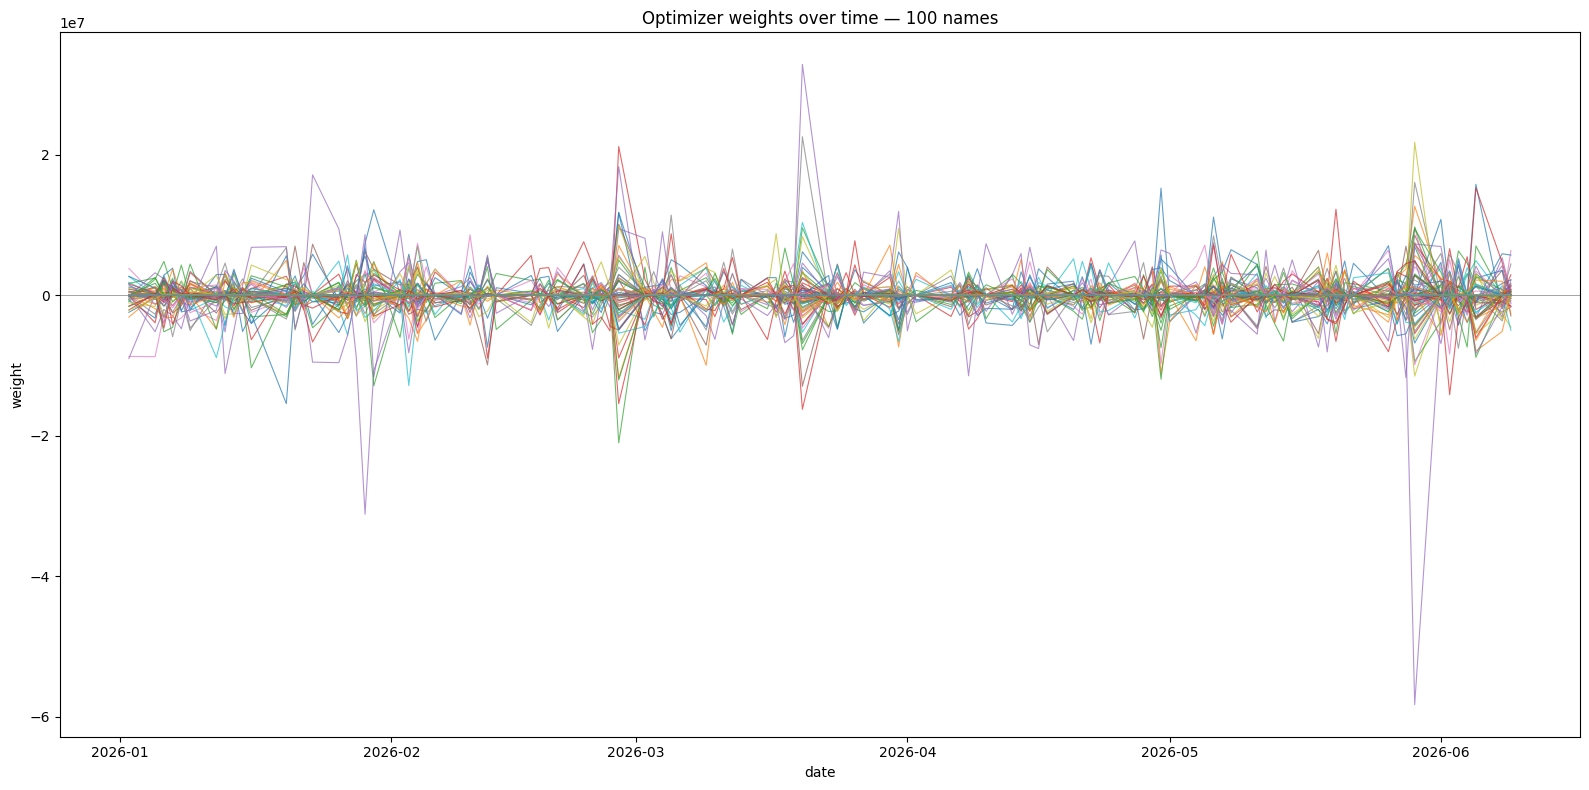

In [9]:
# Optimizer weights over time, one line per symbol (only names ever held)
dates = sorted(weights.keys())

held = sorted({s for d in dates for s, wv in weights[d].items()})

fig, ax = plt.subplots(figsize=(16, 8))
for s in held:
    series = [weights[d].get(s, 0.0) for d in dates]
    ax.plot(dates, series, lw=0.8, alpha=0.7)

ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("date")
ax.set_ylabel("weight")
ax.set_title(f"Optimizer weights over time — {len(held)} names")
fig.tight_layout()
plt.show()

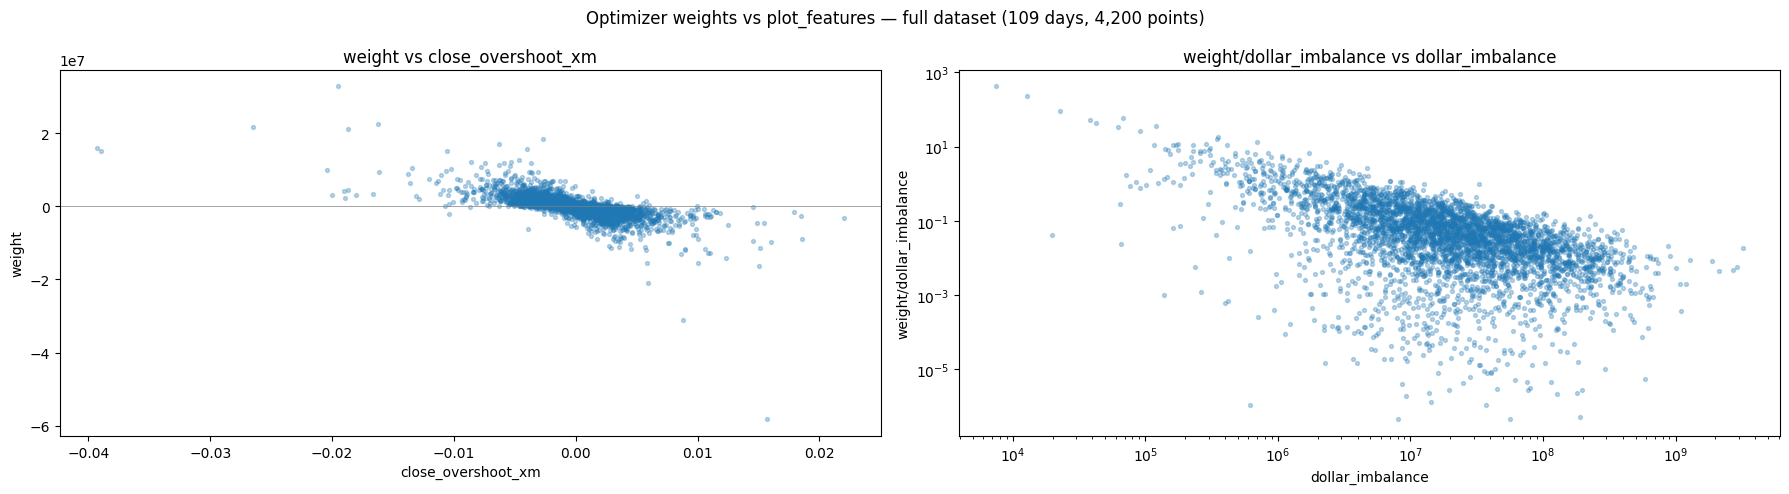

In [10]:
# Scatter weights vs day features over the FULL dataset (all dates pooled)
# Flatten {date: {symbol: w}} -> long frame, then join each day's features from `data`.
w_long = pl.DataFrame(
    {
        "date": [d for d in weights for _ in weights[d]],
        "symbol": [s for d in weights for s in weights[d]],
        "weight": [wv for d in weights for wv in weights[d].values()],
    }
).with_columns(pl.col("symbol").cast(pl.Categorical))

plot_df = test_data.join(w_long, on=["date", "symbol"], how="inner")

weights_arr = plot_df["weight"].to_numpy()
log_x = {"dollar_imbalance", "ADV"}   # positive, span orders of magnitude; signed ratio stays linear
plot_features = features + ["dollar_imbalance"]

fig, axes = plt.subplots(int(len(plot_features)/2), 2, figsize=(18, 5))
for ax, feat in zip(np.atleast_1d(axes).flat, plot_features):
    x = plot_df[feat].to_numpy()
    if feat == "dollar_imbalance":
        lower = np.quantile(x, 0)
        upper = np.quantile(x, 1)
        q_mask = (x>lower) & (x<upper)
        ax.scatter(x[q_mask],
                    np.abs(weights_arr[q_mask]) / x[q_mask],
                    alpha=0.3, s=8)
        ax.set_ylabel("weight/dollar_imbalance")
        ax.set_xlabel("dollar_imbalance")
        ax.set_title(f"weight/dollar_imbalance vs {feat}")
    else:
        ax.scatter(x, weights_arr, alpha=0.3, s=8)
        ax.axhline(0, color="grey", lw=0.5)
        ax.set_xlabel(feat)
        ax.set_ylabel("weight")
        ax.set_title(f"weight vs {feat}")
    if feat in log_x:
        ax.set_xscale("log")
        ax.set_yscale("log")

fig.suptitle(f"Optimizer weights vs plot_features — full dataset ({len(weights)} days, {len(plot_df):,} points)")
fig.tight_layout()
plt.show()

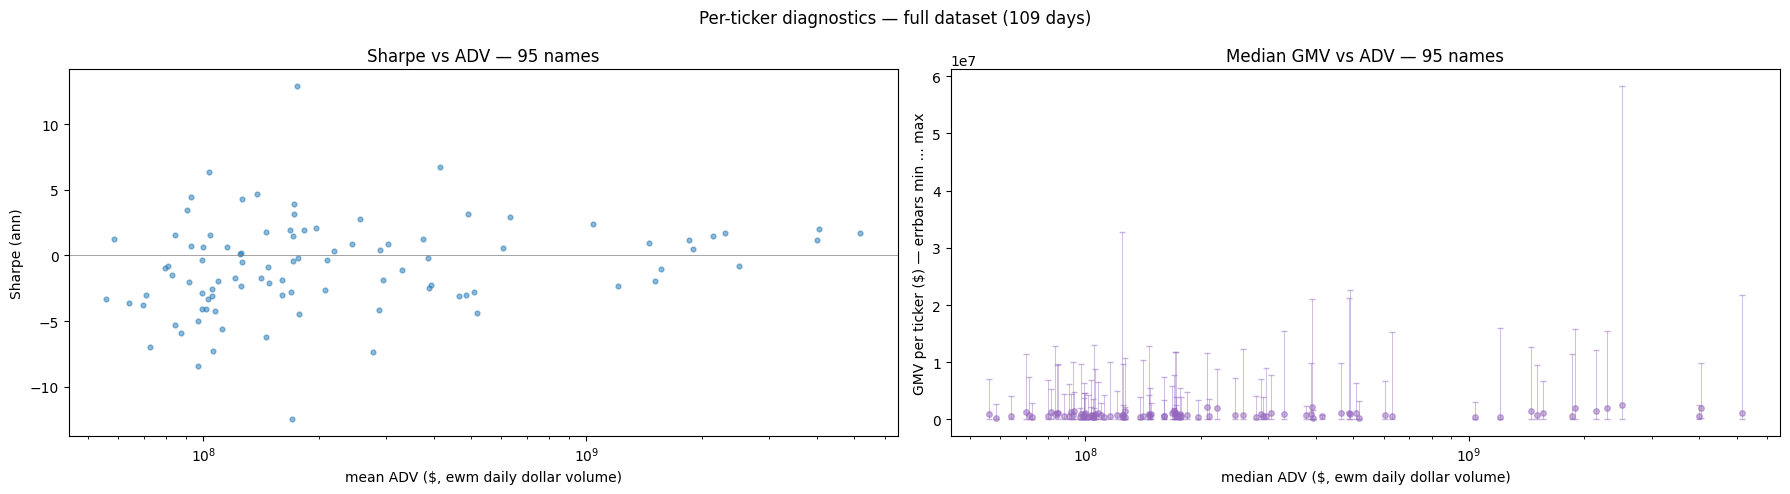

In [11]:
# Per-ticker scatters over the FULL dataset: Sharpe vs ADV, and mean GMV vs ADV.
# Rebuilds per-name daily net PnL with the SAME cost model as the PnL cell below,
# then collapses to one point per ticker:
#   - Sharpe_i  = mean_t(net_pnl_i,t) / std_t(net_pnl_i,t) * sqrt(252)   (zero-position days included)
#   - GMV_i,t   = |$pos_i,t|  -> mean per ticker, with bars spanning its min..max
#   - ADV_i     = mean of the day's ewm daily dollar volume for that name
ANN = 252

pos_long = pl.DataFrame({
    "date":       [d for d in weights for _ in weights[d]],
    "symbol":     [s for d in weights for s in weights[d]],
    "dollar_pos": [w for d in weights for w in weights[d].values()],
}).with_columns(pl.col("symbol").cast(pl.Categorical))

name_daily = (
    test_data
    .join(pos_long, on=["date", "symbol"], how="inner")
    .with_columns((pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("ret_to_close"))
    .with_columns((COMMISSION_PER_SHARE / pl.col("entry_price")).alias("comm_rate"))
    .with_columns(
        (0.5 * pl.col("spread_return") + 2.0 * pl.col("comm_rate"))
            .clip(lower_bound=0.0).alias("cost_rate")
    )
    .with_columns(
        (pl.col("dollar_pos") * pl.col("ret_to_close")
         - pl.col("dollar_pos").abs() * pl.col("cost_rate")).alias("net_pnl_name"),
        pl.col("dollar_pos").abs().alias("gmv_name"),
    )
)

per_name = (
    name_daily
    .group_by("symbol")
    .agg(
        (pl.col("net_pnl_name").mean() / pl.col("net_pnl_name").std(ddof=1) * np.sqrt(ANN)).alias("sharpe"),
        pl.col("ADV").mean().alias("adv_mean"),
        pl.col("gmv_name").mean().alias("gmv_mean"),
        pl.col("gmv_name").median().alias("gmv_median"),
        pl.col("gmv_name").min().alias("gmv_min"),
        pl.col("gmv_name").max().alias("gmv_max"),
        pl.len().alias("n_days"),
    )
    .filter((pl.col("n_days") > 1) & pl.col("sharpe").is_finite())
    .sort("adv_mean")
)

adv      = per_name["adv_mean"].to_numpy()
sharpe_n = per_name["sharpe"].to_numpy()
gmv_median = per_name["gmv_median"].to_numpy()
gmv_lo   = gmv_median - per_name["gmv_min"].to_numpy()   # bar down to min (>= 0)
gmv_hi   = per_name["gmv_max"].to_numpy() - gmv_median   # bar up to max   (>= 0)

fig, (axS, axG) = plt.subplots(1, 2, figsize=(18, 5))

axS.scatter(adv, sharpe_n, alpha=0.5, s=12)
axS.axhline(0, color="grey", lw=0.5)
axS.set_xscale("log")
axS.set_xlabel("mean ADV ($, ewm daily dollar volume)")
axS.set_ylabel("Sharpe (ann)")
axS.set_title(f"Sharpe vs ADV — {len(per_name)} names")

axG.errorbar(adv, gmv_median, yerr=[gmv_lo, gmv_hi], fmt="o", ms=4, alpha=0.5,
             elinewidth=0.6, capsize=2, color="tab:purple")
axG.set_xscale("log")
# axG.set_yscale("log")
axG.set_xlabel("median ADV ($, ewm daily dollar volume)")
axG.set_ylabel("GMV per ticker ($) — errbars min ... max")
axG.set_title(f"Median GMV vs ADV — {len(per_name)} names")

fig.suptitle(f"Per-ticker diagnostics — full dataset ({len(weights)} days)")
fig.tight_layout()
plt.show()

Days traded:        109
Mean GMV:           $62,602,567
Median GMV:         $52,082,303
Max GMV:            $332,302,726  (5.3x mean GMV)
Gross PnL:          $-780,599
Total cost:         $5,851,832
Total impact:       $2,368,224
Total net PnL:      $-9,000,654
Max drawdown:       $-11,481,463.5
Sharpe (ann):       -2.55
Daily hit rate:     40.4%


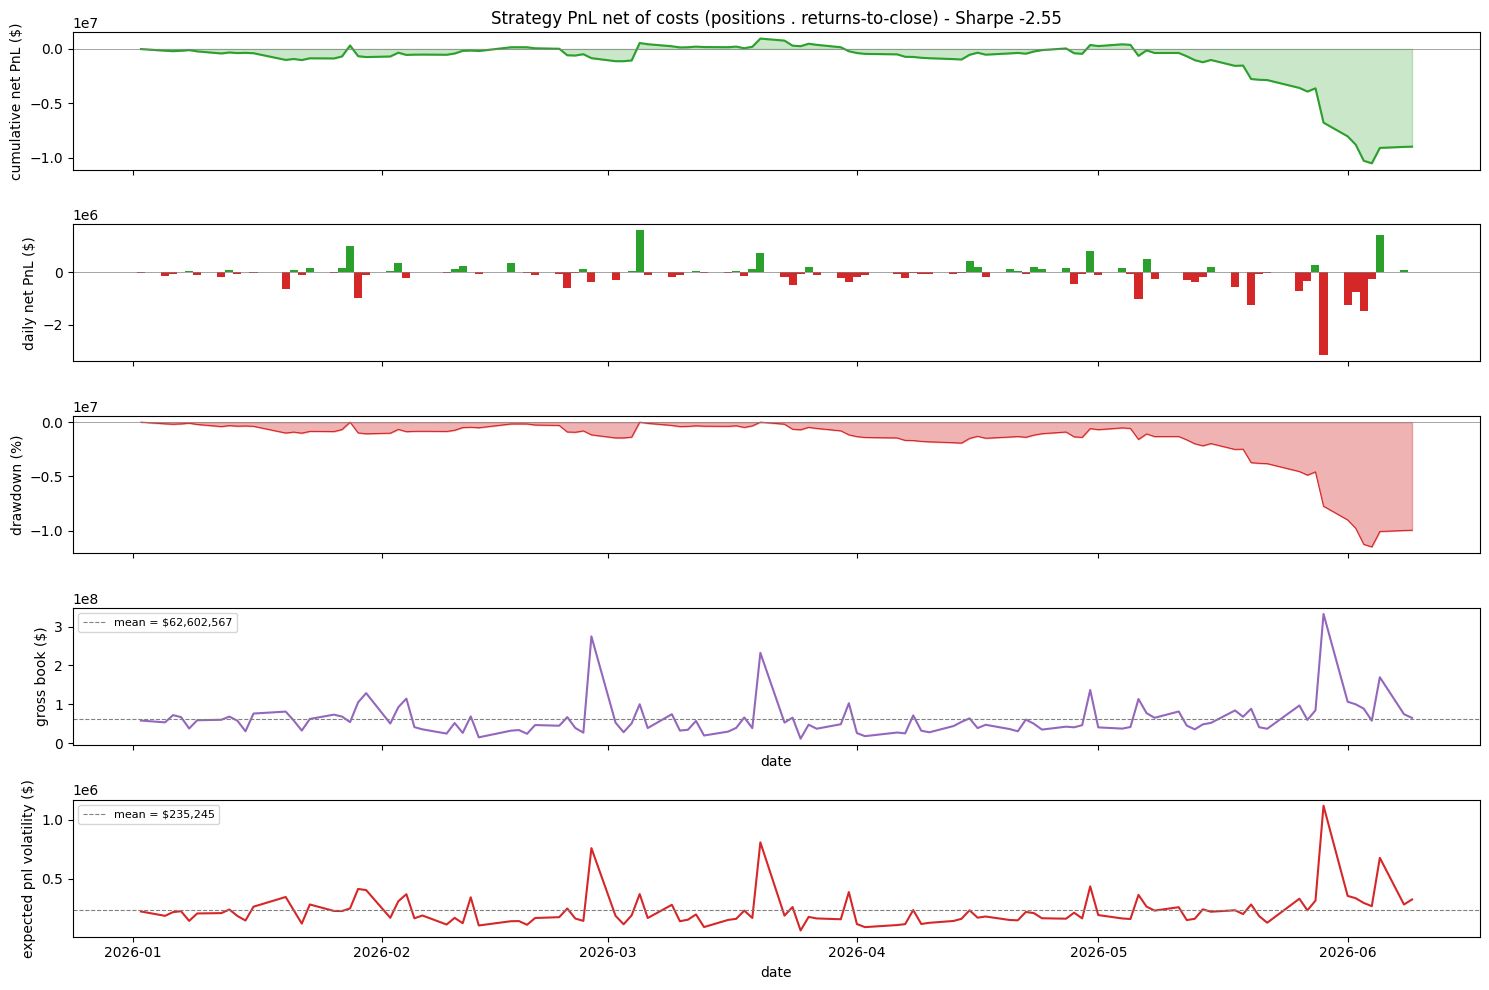

In [12]:
# ===== Strategy PnL: dollar positions . returns-to-close, net of costs =====
# `weights` is the optimizer's ABSOLUTE-DOLLAR book per day: {date: {symbol: $ position}}.
# Daily gross PnL = sum_i (dollar position_i) * (OVERNIGHT return from the close cross to the next open cross_i).
# Costs charged as a dot product  |$pos| . cost_rate:
#   - spread:     HALF of `spread_return`, which here is close_spread + next_open_spread -> one
#                 half-spread at EACH auction (entry in the close cross, exit in the open cross).
#   - commission: $0.0035/share on BOTH legs.
#   - impact:     square-root law  gamma * sigma_i * |$pos_i|^{3/2} / sqrt(ADV$_i)  (gamma scalar; sigma_i and
#                 ADV$ are BOTH causal EWMA per-(name,date) columns on test_data).  Same impact the optimizer
#                 trades off: it charges gamma*sqrt(scale)*sum_i sigma_i*|x_i|^{3/2}/sqrt(ADV$_i).
ANN = 252


# Flatten {date: {symbol: $pos}} -> long, then join the day's prices/spread from `data`.
pos_long = pl.DataFrame({
    "date":       [d for d in weights for _ in weights[d]],
    "symbol":     [s for d in weights for s in weights[d]],
    "dollar_pos": [w for d in weights for w in weights[d].values()],
}).with_columns(pl.col("symbol").cast(pl.Categorical))

pnl_daily = (
    test_data
    .join(pos_long, on=["date", "symbol"], how="inner")
    .with_columns((pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("ret_to_close"))
    .with_columns(
        (pl.col("dollar_pos") * pl.col("ret_to_close")).alias("gross_pnl"),                       # $pos . return
        (COMMISSION_PER_SHARE / pl.col("entry_price")).alias("comm_rate"),                        # per-leg commission, as a return
    )
    # spread_return is close_spread + next_open_spread; charging half of it prices one half-spread
    # at each of the two auction legs + commission on BOTH legs.
    .with_columns(
        (0.5 * pl.col("spread_return") + 2.0 * pl.col("comm_rate"))
            .clip(lower_bound=0.0).alias("cost_rate"),
    )
    .with_columns(
        (pl.col("dollar_pos").abs() * pl.col("cost_rate")).alias("cost"),                         # dot product: |$pos| . cost_rate
        (IMPACT_GAMMA * pl.col("vol") * pl.col("dollar_pos").abs() ** 1.5 / pl.col("ADV").sqrt()).alias("impact"),  # gamma*sigma_i*|Q$|^{3/2}/sqrt(ADV$)
    )
    .with_columns(
        (pl.col("gross_pnl")
         - pl.col("cost")
         - pl.col("impact")).alias("net_pnl_name"),
    )
    .group_by("date")
    .agg(
        pl.col("net_pnl_name").sum().alias("net_pnl"),
        pl.col("gross_pnl").sum().alias("gross_pnl"),
        pl.col("cost").sum().alias("cost"),
        pl.col("impact").sum().alias("impact"),                # daily sqrt-law impact charge
        pl.col("dollar_pos").abs().sum().alias("GMV"),         # gross book deployed that day
    )
    .sort("date")
    .with_columns(pl.col("net_pnl").cum_sum().alias("cum_pnl"))
)

# ----- stats -----
pnl  = pnl_daily["net_pnl"].to_numpy()
cum_pnl  = pnl_daily["cum_pnl"].to_numpy()
mean_gmv = pnl_daily["GMV"].mean()
median_gmv = pnl_daily["GMV"].median()
rolling_mean_gmv = pnl_daily["GMV"].ewm_mean(alpha=0.06, adjust=True)
max_gmv = pnl_daily["GMV"].max()
# -- factor decomposition for expected risk --
# √ (xᵀ @ Σ @ x) = √ [ (L @ x)ᵀ @ Σ_𝘍 @ (L @ x) + (xᵀ @ D @ x) ]
exp_vol = [
    np.sqrt(
        np.transpose((L @ np.array([weights[d][s] for s in ACTIVE_SET])))
        @ SIGMA_F
        @ (L @ np.array([weights[d][s] for s in ACTIVE_SET]))
        + np.sum(EPS_DIAG*np.array([weights[d][s] for s in ACTIVE_SET])**2)
    ) for d in weights
]

# Drawdown of the cumulative net-PnL curve (underwater, in $): current - running peak (<= 0).
peak      = np.maximum.accumulate(cum_pnl)
drawdown  = (cum_pnl - peak)
max_dd    = drawdown.min()                          # deepest trough ($, <= 0)

sharpe  = pnl.mean() / pnl.std(ddof=1) * np.sqrt(ANN)

print(f"Days traded:        {len(pnl)}")
print(f"Mean GMV:           ${mean_gmv:,.0f}")
print(f"Median GMV:         ${median_gmv:,.0f}")
print(f"Max GMV:            ${max_gmv:,.0f}  ({max_gmv / mean_gmv:,.1f}x mean GMV)")
print(f"Gross PnL:          ${pnl_daily['gross_pnl'].sum():,.0f}")
print(f"Total cost:         ${pnl_daily['cost'].sum():,.0f}")
print(f"Total impact:       ${pnl_daily['impact'].sum():,.0f}")
print(f"Total net PnL:      ${pnl.sum():,.0f}")
print(f"Max drawdown:       ${max_dd:,.1f}")
print(f"Sharpe (ann):       {sharpe:.2f}")
print(f"Daily hit rate:     {(pnl > 0).mean():.1%}")

# ----- plots: cumulative PnL, daily PnL, drawdown, gross book -----
dts   = pnl_daily["date"].to_list()
gmv = pnl_daily["GMV"].to_numpy()
fig, (ax_pnl, ax_bar, ax_dd, ax_gmv, ax_vol) = plt.subplots(5, 1, figsize=(15, 10), sharex=True, height_ratios=[1, 1, 1, 1, 1])

ax_pnl.plot(dts, cum_pnl, color="tab:green")
ax_pnl.fill_between(dts, cum_pnl, color="tab:green", alpha=0.25)
ax_pnl.axhline(0, color="grey", lw=0.5)
ax_pnl.set_ylabel("cumulative net PnL ($)")
ax_pnl.set_title(f"Strategy PnL net of costs (positions . returns-to-close) - Sharpe {sharpe:.2f}")

ax_bar.bar(dts, pnl, color=np.where(pnl >= 0, "tab:green", "tab:red"), width=1.0)
ax_bar.axhline(0, color="grey", lw=0.5)
ax_bar.set_ylabel("daily net PnL ($)")

# Underwater curve: distance below the running high-water mark of cumulative PnL.
ax_dd.fill_between(dts, drawdown, 0.0, color="tab:red", alpha=0.35)
ax_dd.plot(dts, drawdown, color="tab:red", lw=0.8)
ax_dd.axhline(0, color="grey", lw=0.5)
dd_idx = int(np.argmin(drawdown))
# ax_dd.annotate(f"max DD {max_dd*100:,.1f}%", xy=(dts[dd_idx], max_dd),
#                xytext=(5, 8), textcoords="offset points", fontsize=8, color="tab:red")
ax_dd.set_ylabel("drawdown (%)")

ax_gmv.plot(dts, gmv, color="tab:purple")
ax_gmv.axhline(mean_gmv, color="grey", lw=0.8, ls="--", label=f"mean = ${mean_gmv:,.0f}")
ax_gmv.set_ylabel("gross book ($)")
ax_gmv.set_xlabel("date")
ax_gmv.legend(loc="upper left", fontsize=8)

ax_vol.plot(dts, exp_vol, color="tab:red")
ax_vol.axhline(np.nanmean(exp_vol), color="grey", lw=0.8, ls="--", label=f"mean = ${np.nanmean(exp_vol):,.0f}")
ax_vol.set_ylabel("expected pnl volatility ($)")
ax_vol.set_xlabel("date")
ax_vol.legend(loc="upper left", fontsize=8)
# ax_vol.ticklabel_format(style='plain', axis='y', useOffset=False)


fig.tight_layout()
plt.show()

#### Some diagnostics

In [13]:
ANN = 252
alpha_by_day = {d: a for d, a, _, _, _ in day_records}      # dense alpha, ACTIVE_SET order
cost_by_day = {d: c for d, _, c, _, _ in day_records}

exante = []
for d in sorted(weights):
    x = np.array([weights[d][s] for s in ACTIVE_SET])            # $ positions, same order
    a = alpha_by_day[d]                                          # expected returns
    exp_pnl = a @ x - cost_by_day[d] @ np.abs(x)                 # net expected daily $ PnL
    exp_var = (L @ x) @ SIGMA_F @ (L @ x) + np.sum(EPS_DIAG * x**2)   # matches optimizer's risk term
    exante.append(exp_pnl / np.sqrt(exp_var) if exp_var > 0 else np.nan)

exante = np.array(exante)
print(f"Mean expected $vol:   {np.nanmean([np.sqrt(np.transpose((L@np.array([weights[d][s] for s in ACTIVE_SET])))@SIGMA_F@(L@np.array([weights[d][s] for s in ACTIVE_SET])) + np.sum(EPS_DIAG*np.array([weights[d][s] for s in ACTIVE_SET])**2)) for d in weights]):,.0f}")
print(f"Max expected $vol:   {np.nanmax([np.sqrt((L@np.array([weights[d][s] for s in ACTIVE_SET]))@SIGMA_F@(L@np.array([weights[d][s] for s in ACTIVE_SET])) + np.sum(EPS_DIAG*np.array([weights[d][s] for s in ACTIVE_SET])**2)) for d in weights]):,.0f}")

Mean expected $vol:   235,245
Max expected $vol:   1,116,989


In [14]:
from scipy.stats import pearsonr, spearmanr
r, pval = spearmanr(pnl_daily["GMV"], pnl_daily["cum_pnl"])
print(f"Spearman Corr of GMV and PnL: {r:,.5f}")

Spearman Corr of GMV and PnL: -0.26857


In [15]:
pnl_daily

date,net_pnl,gross_pnl,cost,impact,GMV,cum_pnl
date,f64,f64,f64,f64,f64,f64
2026-01-02,-16281.704216,33014.563609,37706.353989,11589.913836,5.8155e7,-16281.704216
2026-01-05,-151008.354216,-96838.763963,41348.420742,12821.16951,5.3530e7,-167290.058431
2026-01-06,-41332.987051,27345.369524,52530.699595,16147.656979,7.2209e7,-208623.045482
2026-01-07,34306.432957,97882.779448,47702.719658,15873.626833,6.6798e7,-174316.612525
2026-01-08,61843.125521,105262.63703,32001.162581,11418.348928,3.7729e7,-112473.487004
…,…,…,…,…,…,…
2026-06-03,-1.4836e6,-1.3621e6,88447.204182,32972.033747,8.8801e7,-1.0299e7
2026-06-04,-233356.184833,-150182.041535,60996.551705,22177.591593,5.7760e7,-1.0533e7
2026-06-05,1.4167e6,1.6338e6,138986.171454,78096.122114,1.6950e8,-9.1159e6


### Parameter Sweeps

⚠️ Expensive: each point re-solves every day. Run deliberately.

In [ ]:
def _solve_all_weights(lam, vol_cap):
    """Solve every day at (lam, vol_cap); return {date: {symbol: $pos}}."""
    chunks = [c for c in _split_contiguous(day_records, N_JOBS) if c]
    chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
        delayed(_solve_chunk)(ACTIVE_SET, SIGMA_R, SIGMA_F, L, EPS_DIAG, lam, IMPACT_GAMMA, vol_cap, MAX_DOLLAR_GMV, chunk)
        for chunk in chunks
    )
    return {d: dict(zip(ACTIVE_SET, ws)) for chunk in chunk_results for d, ws in chunk}

def _sweep_point(lam, vol_cap):
    """Solve all days at (lam, vol_cap), then run the SAME net-of-cost + 3/2-power impact
    accounting as the main PnL cell. Returns (mean_gmv, std_gmv, total_net_pnl)."""
    weights_d = _solve_all_weights(lam, vol_cap)
    pos_long = pl.DataFrame({
        "date":       [d for d in weights_d for _ in weights_d[d]],
        "symbol":     [s for d in weights_d for s in weights_d[d]],
        "dollar_pos": [w for d in weights_d for w in weights_d[d].values()],
    }).with_columns(pl.col("symbol").cast(pl.Categorical))
    pdl = (
        test_data
        .join(pos_long, on=["date", "symbol"], how="inner")
        .with_columns((pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("ret_to_close"))
        .with_columns((COMMISSION_PER_SHARE / pl.col("entry_price")).alias("comm_rate"))
        .with_columns((0.5 * pl.col("spread_return") + 2.0 * pl.col("comm_rate"))
                      .clip(lower_bound=0.0).alias("cost_rate"))
        .with_columns(
            (pl.col("dollar_pos") * pl.col("ret_to_close")                 # gross
             - pl.col("dollar_pos").abs() * pl.col("cost_rate")            # spread + commission
             - IMPACT_GAMMA * pl.col("vol") * pl.col("dollar_pos").abs() ** 1.5 / pl.col("ADV").sqrt()   # gamma*sigma_i*|Q$|^{3/2}/sqrt(ADV$)
             ).alias("net_pnl_name"),
            pl.col("dollar_pos").abs().alias("gmv_name"),
        )
        .group_by("date")
        .agg(pl.col("net_pnl_name").sum().alias("net_pnl"),
             pl.col("gmv_name").sum().alias("GMV"))
    )
    gmv = pdl["GMV"].to_numpy()
    return float(gmv.mean()), float(gmv.std()), float(pdl["net_pnl"].sum())

# --- Sweep grids ---
lambda_grid = np.geomspace(1e-8, 1e-5, 100)            # risk aversion per dollar (~ 1/ intended capital)

sweep         = [_sweep_point(lam, 1 * int(1/lam)) for lam in lambda_grid]
gmv_vs_lambda = [(mean, std) for (mean, std, _) in sweep]   # (mean_gmv, std_gmv) — used by the plot cell
pnl_vs_lambda = [pnl for (_, _, pnl) in sweep]              # total net PnL per lambda

In [ ]:
# --- Plots: GMV + net PnL for each sweep ---
fig, (ax_mean, ax_std, ax_pnl) = plt.subplots(3, 1, figsize=(15, 8), sharex=True)

best_i   = int(np.nanargmax(pnl_vs_lambda))
best_lam = lambda_grid[best_i]
best_gmv = gmv_vs_lambda[best_i][0]
best_pnl = pnl_vs_lambda[best_i]



ax_mean.plot(lambda_grid, [mean for (mean, std) in gmv_vs_lambda], marker="o", color="tab:blue")
ax_mean.set_ylabel("Mean GMV ($)")
ax_mean.set_title(f"Mean of Daily GMV vs Lambda")

ax_std.plot(lambda_grid, [std for (mean, std) in gmv_vs_lambda], marker="o", color="tab:red")
ax_std.set_ylabel("Volatilty of GMV ($)")
ax_std.set_title("Volatilty of Daily GMV vs Lambda")
# ax_std.set_yscale("log")

# Total net PnL (net of spread, commission, quadratic impact) vs lambda. Linear y: PnL can be < 0.
ax_pnl.plot(lambda_grid, pnl_vs_lambda, marker="o", color="tab:green")
ax_pnl.axhline(0, color="grey", lw=0.5)
ax_pnl.set_xlabel("Lambda")
ax_pnl.set_ylabel("PnL ($)")
ax_pnl.set_title("Total Net PnL vs Lambda")
ax_pnl.set_xscale("log")
# ax_pnl.legend()


fig.tight_layout()
plt.show()

print(f"Max PNL:   ${best_pnl:,.0f}")
print(f"GMV:       ${best_gmv:,.0f}"
      f"\n*Lambda:   {best_lam:,.2e}")

In [ ]:
def _solve_all_weights_gam(gam):
    """Solve every day at (lam, vol_cap); return {date: {symbol: $pos}}."""
    chunks = [c for c in _split_contiguous(day_records, N_JOBS) if c]
    chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
        delayed(_solve_chunk)(ACTIVE_SET, SIGMA_R, SIGMA_F, L, EPS_DIAG, LAMBDA, gam, DAILY_DOLLAR_VOL_CAP, MAX_DOLLAR_GMV, chunk)
        for chunk in chunks
    )
    return {d: dict(zip(ACTIVE_SET, ws)) for chunk in chunk_results for d, ws in chunk}

def _sweep_point_gam(gam):
    """Solve all days at (lam, vol_cap), then run the SAME net-of-cost + 3/2-power impact
    accounting as the main PnL cell. Returns (mean_gmv, std_gmv, total_net_pnl)."""
    weights_d = _solve_all_weights_gam(gam)
    pos_long = pl.DataFrame({
        "date":       [d for d in weights_d for _ in weights_d[d]],
        "symbol":     [s for d in weights_d for s in weights_d[d]],
        "dollar_pos": [w for d in weights_d for w in weights_d[d].values()],
    }).with_columns(pl.col("symbol").cast(pl.Categorical))
    pdl = (
        test_data
        .join(pos_long, on=["date", "symbol"], how="inner")
        .with_columns((pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("ret_to_close"))
        .with_columns((COMMISSION_PER_SHARE / pl.col("entry_price")).alias("comm_rate"))
        .with_columns((0.5 * pl.col("spread_return") + 2.0 * pl.col("comm_rate"))
                      .clip(lower_bound=0.0).alias("cost_rate"))
        .with_columns(
            (pl.col("dollar_pos") * pl.col("ret_to_close")                 # gross
             - pl.col("dollar_pos").abs() * pl.col("cost_rate")            # spread + commission
             - gam * pl.col("vol") * pl.col("dollar_pos").abs() ** 1.5 / pl.col("ADV").sqrt()   # gamma*sigma_i*|Q$|^{3/2}/sqrt(ADV$)
             ).alias("net_pnl_name"),
            pl.col("dollar_pos").abs().alias("gmv_name"),
        )
        .group_by("date")
        .agg(pl.col("net_pnl_name").sum().alias("net_pnl"),
             pl.col("gmv_name").sum().alias("GMV"))
    )
    gmv = pdl["GMV"].to_numpy()
    return float(gmv.mean()), float(gmv.std()), float(pdl["net_pnl"].sum())

# --- Sweep grids ---
gamma_grid = np.linspace(0.01, 1, 100)            # price impact calibration

sweep         = [_sweep_point_gam(gam) for gam in gamma_grid]
gmv_vs_gamma = [(mean, std) for (mean, std, _) in sweep]   # (mean_gmv, std_gmv) — used by the plot cell
pnl_vs_gamma = [pnl for (_, _, pnl) in sweep]              # total net PnL per lambda

In [ ]:
# --- Plots: GMV + net PnL for each sweep ---
fig, (ax_mean, ax_std, ax_pnl) = plt.subplots(3, 1, figsize=(15, 8), sharex=True)

best_i   = int(np.nanargmax(gmv_vs_gamma))
best_lam = gamma_grid[best_i]
best_gmv = gmv_vs_gamma[best_i][0]
best_pnl = pnl_vs_gamma[best_i]



ax_mean.plot(gamma_grid, [mean for (mean, std) in gmv_vs_gamma], marker="o", color="tab:blue")
ax_mean.set_ylabel("Mean GMV ($)")
ax_mean.set_title("Mean of Daily GMV vs Gamma")

ax_std.plot(gamma_grid, [std for (mean, std) in gmv_vs_gamma], marker="o", color="tab:red")
ax_std.set_ylabel("Volatilty of GMV ($)")
ax_std.set_title("Volatilty of Daily GMV vs Gamma")

# Total net PnL (net of spread, commission, quadratic impact) vs lambda. Linear y: PnL can be < 0.
ax_pnl.plot(gamma_grid, pnl_vs_gamma, marker="o", color="tab:green")
ax_pnl.axhline(0, color="grey", lw=0.5)
ax_pnl.set_xlabel("Gamma")
ax_pnl.set_ylabel("PnL ($)")
ax_pnl.set_title("Total Net PnL vs Gamma")
# ax_pnl.set_xscale("log")


fig.tight_layout()
plt.show()

print(f"Max PNL:   ${best_pnl:,.0f}")
print(f"GMV:       ${best_gmv:,.0f}"
      f"\n*Gamma:   {best_lam:,.2e}")

### Notes
- Everything from the optimizer classes down is the same code as `../optimizer/optimal_portfolio.ipynb`.
  The three deliberate departures:
  1. **Data / horizon** — entry in the close cross, exit in the next open cross, so `entry_price`,
     `auction_price`, `return_to_close` and `spread_return` carry the overnight meaning documented at the top.
  2. **Forecast** — refit in-notebook (`Ridge(alpha=1)` on `close_overshoot_xm`) rather than loading
     `../forecast/forecast_pipe.joblib`, because that pipeline forecasts a different target.
  3. **`ImpactModel.get_imbalance_caps`** — names absent from a day's cross-section now keep a cap of
     **0** instead of inheriting the smallest present cap. Here we trade only the large-auction subset,
     so ~half the universe is untradable each day and would otherwise be usable by the factor-neutrality
     equalities while being silently dropped from the PnL join.
- For our covariance we are using a factor model on causal-voltility-standardized returns. This is for
  better estimation and numerical sparsity. We then use a sample volatility value (with a floor) to get
  the model back into return units. It is a **close-to-close daily** covariance being applied to an
  **overnight** holding period — conservative, but the right fix is an overnight-specific risk model.

### Next:
- The costs question is sharper here than in the close strategy: the study's own caveat is that the edge
  is a few bps and the round trip crosses two auctions. The half-spread-at-each-auction charge is a proxy;
  an auction-specific cost model (MOC/MOO participation vs. imbalance) would be the honest version.
- Overnight risk is real risk: consider tightening the vol cap / lambda relative to the intraday strategy,
  and neutralizing to the factor set the optimizer already uses over the *overnight* covariance.
- The alpha is weak (mean daily IC ~0.03 in CV, +0.09 on the Jan-2026 validation month). Check whether the
  sweeps below ever produce net PnL that survives costs before scaling GMV.
- Same universe caveats as the parent notebook: `ACTIVE_SET` is fixed, ignores renames, and should really
  be a rolling top-N by ADV with the forecast/covariance/impact models refit per period.

In [ ]:
# ===== 2-D parameter sweep: lambda x volatility cap =====
# For each (lambda, vol_cap) on the grid, solve every day and run the SAME net-of-cost +
# 3/2-power impact accounting as the main PnL cell. Records mean daily GMV, total net PnL,
# and annualized Sharpe at each node. Unlike the 1-D sweep above, lambda and the vol cap are
# swept INDEPENDENTLY (not tied on a ray). Reuses _solve_all_weights from the
# 1-D sweep cell above — run that cell first.
ANN = 252

def _grid_point(lam, vol_cap):
    """Solve all days at (lam, vol_cap); return (mean_gmv, total_net_pnl, sharpe)."""
    weights_d = _solve_all_weights(lam, vol_cap)
    pos_long = pl.DataFrame({
        "date":       [d for d in weights_d for _ in weights_d[d]],
        "symbol":     [s for d in weights_d for s in weights_d[d]],
        "dollar_pos": [w for d in weights_d for w in weights_d[d].values()],
    }).with_columns(pl.col("symbol").cast(pl.Categorical))
    pdl = (
        test_data
        .join(pos_long, on=["date", "symbol"], how="inner")
        .with_columns((pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("ret_to_close"))
        .with_columns((COMMISSION_PER_SHARE / pl.col("entry_price")).alias("comm_rate"))
        .with_columns((0.5 * pl.col("spread_return") + 2.0 * pl.col("comm_rate"))
                      .clip(lower_bound=0.0).alias("cost_rate"))
        .with_columns(
            (pl.col("dollar_pos") * pl.col("ret_to_close")                 # gross
             - pl.col("dollar_pos").abs() * pl.col("cost_rate")            # spread + commission
             - IMPACT_GAMMA * pl.col("vol") * pl.col("dollar_pos").abs() ** 1.5 / pl.col("ADV").sqrt()   # gamma*sigma_i*|Q$|^{3/2}/sqrt(ADV$)
             ).alias("net_pnl_name"),
            pl.col("dollar_pos").abs().alias("gmv_name"),
        )
        .group_by("date")
        .agg(pl.col("net_pnl_name").sum().alias("net_pnl"),
             pl.col("gmv_name").sum().alias("GMV"))
    )
    pnl = pdl["net_pnl"].to_numpy()
    sd  = pnl.std(ddof=1)
    return (float(pdl["GMV"].mean()),
            float(pnl.sum()),
            float(pnl.mean() / sd * np.sqrt(ANN)) if sd > 0 else np.nan)

# --- Grid axes (edit ranges/resolution to taste; cost ~ n_lam * n_volcap full solves) ---
lam_grid    = np.geomspace(1e-9, 1e-5, 25)     # risk aversion per dollar
volcap_grid = np.geomspace(1e4, 1e8, 25)       # target daily $ volatility cap

# Surfaces, shape (n_volcap, n_lambda): rows = vol cap, cols = lambda.
GMV_grid    = np.full((len(volcap_grid), len(lam_grid)), np.nan)
PNL_grid    = np.full((len(volcap_grid), len(lam_grid)), np.nan)
SHARPE_grid = np.full((len(volcap_grid), len(lam_grid)), np.nan)
for i, vc in enumerate(volcap_grid):
    for j, lam in enumerate(lam_grid):
        GMV_grid[i, j], PNL_grid[i, j], SHARPE_grid[i, j] = _grid_point(lam, vc)
    print(f"vol cap {vc:.1e} done ({i + 1}/{len(volcap_grid)})")

# --- Argmax over total net PnL: report lambda / vol cap / GMV / Sharpe there ---
best_i, best_j = np.unravel_index(np.nanargmax(PNL_grid), PNL_grid.shape)
best = {
    "lambda":  float(lam_grid[best_j]),
    "vol_cap": float(volcap_grid[best_i]),
    "gmv":     float(GMV_grid[best_i, best_j]),
    "pnl":     float(PNL_grid[best_i, best_j]),
    "sharpe":  float(SHARPE_grid[best_i, best_j]),
}
print(f"\nMax net PnL ${best['pnl']:,.0f} at "
      f"lambda={best['lambda']:.3e}, vol_cap={best['vol_cap']:.3e} "
      f"(mean GMV ${best['gmv']:,.0f}, Sharpe {best['sharpe']:.2f})")
best

In [ ]:
# --- Plots: GMV / net PnL / Sharpe surfaces over the (lambda, vol_cap) grid ---
def _heat(ax, Z, title, cmap, diverging=False):
    kw = {}
    if diverging:
        v = float(np.nanmax(np.abs(Z)))
        kw = {"vmin": -v, "vmax": v}            # center the diverging map at 0
    pcm = ax.pcolormesh(lam_grid, volcap_grid, Z, shading="nearest", cmap=cmap, **kw)
    fig.colorbar(pcm, ax=ax)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("lambda (risk aversion per $)")
    ax.set_ylabel("vol cap (target daily $ vol)")
    ax.set_title(title)
    ax.scatter([best["lambda"]], [best["vol_cap"]], marker="*", s=250,
               color="white", edgecolor="black", zorder=5, label="max PnL")
    ax.legend(loc="upper right", fontsize=8)

fig, (ax_g, ax_p, ax_s) = plt.subplots(1, 3, figsize=(20, 6))
_heat(ax_g, GMV_grid,    "Mean daily GMV ($)", "viridis")
_heat(ax_p, PNL_grid,    "Total net PnL ($)",  "RdYlGn", diverging=True)
_heat(ax_s, SHARPE_grid, "Sharpe (ann)",       "RdYlGn", diverging=True)

fig.suptitle("2-D sweep: lambda x vol cap  (★ = max total net PnL)")
fig.tight_layout()
plt.show()

print(f"Max total net PnL: ${best['pnl']:,.0f}")
print(f"  lambda:   {best['lambda']:.3e}")
print(f"  vol cap:  {best['vol_cap']:.3e}")
print(f"  mean GMV: ${best['gmv']:,.0f}")
print(f"  Sharpe:   {best['sharpe']:.2f}")